In [104]:
import numpy as np

data = np.load('data/processed/dataset.npz')

X_train = data['X_train']
y_train = data['y_train']
X_val = data['X_val']
y_val = data['y_val']
X_test = data['X_test']
y_test = data['y_test']
class_named = data['class_named']

X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

input_shape = (224, 224, 3)
num_classes = len(class_named)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:  ", X_val.shape)
print("y_val shape:  ", y_val.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)
print("Classes:", class_named)
print("input_shape:", input_shape)
print("num_classes:", num_classes)

X_train shape: (4775, 224, 224, 3)
y_train shape: (4775, 4)
X_val shape:   (843, 224, 224, 3)
y_val shape:   (843, 4)
X_test shape:  (1405, 224, 224, 3)
y_test shape:  (1405, 4)
Classes: ['glioma' 'meningioma' 'notumor' 'pituitary']
input_shape: (224, 224, 3)
num_classes: 4


The general syntax
Conv2D(
    filters,
    kernel_size,
    activation,
    padding
)

In [107]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout


model = Sequential([
    Input(shape=input_shape),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    
    Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [108]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,948 (49.36 MB)

 Trainable params: 12,938,948 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

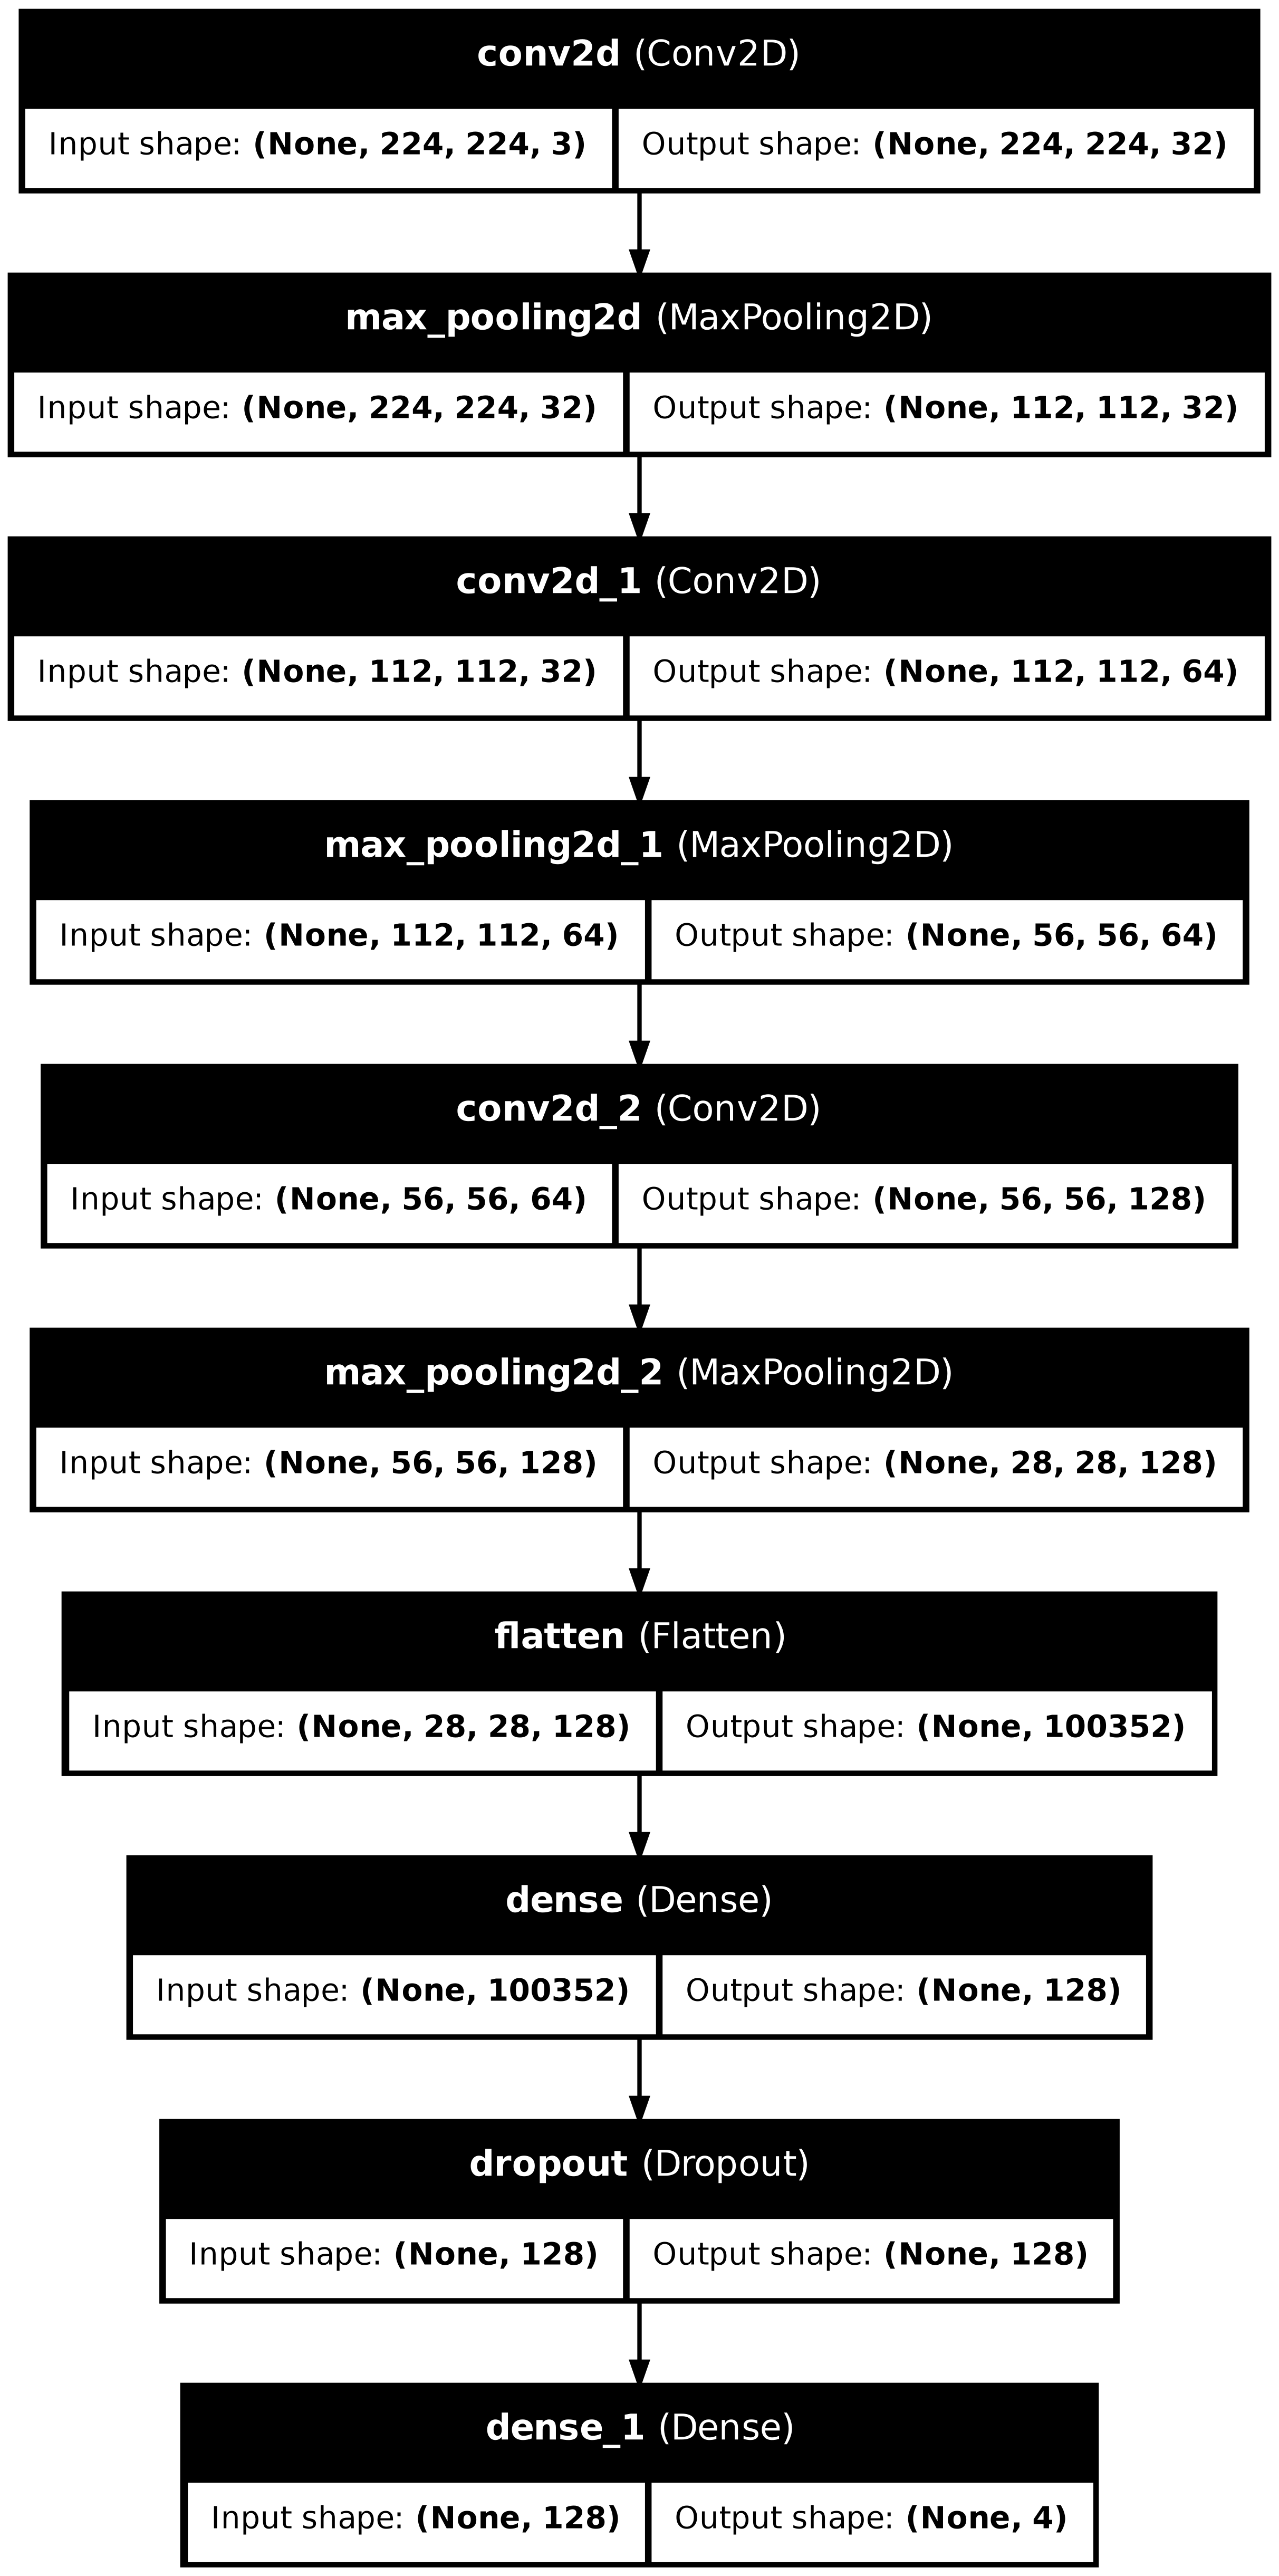

In [109]:
from tensorflow.keras.utils import plot_model
import os
from IPython.display import Image, display


os.makedirs('models',exist_ok=True)

model_img_path = 'models/model.png'

plot_model(
    model,
    to_file=model_img_path,
    show_shapes=True,
    show_layer_names=True,
    dpi=300
)


display(Image(filename=model_img_path))

In [110]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [112]:
import time 


X_subset = X_train[:500]
y_subset = y_train[:500]

X_val_subset = X_val[:200]
y_val_subset = y_val[:200]

subset_classes = np.argmax(y_subset, axis=1)
unique_classes, counts = np.unique(subset_classes, return_counts=True)

print("Class distribution in 500-image subset:")
for cls_idx, count in zip(unique_classes, counts):
    print(f"  {class_named[cls_idx]}: {count} ({count/500*100:.1f}%)")
    
    
start_time = time.time()


history = model.fit(
    X_subset,
    y_subset,
    batch_size=32,
    epochs=2,
    validation_data=(X_val_subset, y_val_subset)
)


end_time = time.time()
duration = end_time - start_time

print(f"test will be finished in {duration:.2f}s")

epochs_planned = 30
time_per_epoch_subset = duration / 2
multiplier = len(X_train) / 500
estimated_full_epoch_time = time_per_epoch_subset * multiplier
estimated_total_minutes = (estimated_full_epoch_time * epochs_planned) / 60

print(f"Estimated time per full epoch: {estimated_full_epoch_time:.1f} seconds")
print(f"Estimated total training time ({epochs_planned} epochs): {estimated_total_minutes:.1f} minutes")

Class distribution in 500-image subset:
  glioma: 109 (21.8%)
  meningioma: 120 (24.0%)
  notumor: 150 (30.0%)
  pituitary: 121 (24.2%)
Epoch 1/2
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 359ms/step - accuracy: 0.3580 - loss: 1.6467 - val_accuracy: 0.4150 - val_loss: 1.1991
Epoch 2/2
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 314ms/step - accuracy: 0.6020 - loss: 0.9835 - val_accuracy: 0.6650 - val_loss: 0.8158
test will be finished in 15.58s
Estimated time per full epoch: 74.4 seconds
Estimated total training time (30 epochs): 37.2 minutes



| Hyperparameter | Value | Reason |
| --- | --- | --- |
| **Learning Rate** | `0.001` | Proved stable and successfully reduced loss during the sanity test without causing divergence. |
| **Batch Size** | `32` | Standard balance providing reliable gradient updates (~150 steps per epoch) and manageable memory usage. |
| **Number of Epochs** | `30` (Max) | Generous upper bound (~50-70 seconds per epoch) designed to let callbacks (`EarlyStopping`) automatically halt training at the optimal point. |